# Phase 5: ABC-XYZ Analysis

## 5.1 ABC Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    'Cleaned_Product_Demand.csv',
    parse_dates=['Date']
)

df.head()

,Product_Code,Warehouse,Product_Category,Date,Order_Demand,Demand_Type
0,Product_0993,Whse_J,Category_028,2012-07-27,100,Positive
1,Product_0979,Whse_J,Category_028,2012-01-19,500,Positive
2,Product_0979,Whse_J,Category_028,2012-02-03,500,Positive
3,Product_0979,Whse_J,Category_028,2012-02-09,500,Positive
4,Product_0979,Whse_J,Category_028,2012-03-02,500,Positive


In [2]:
abc = df[df['Order_Demand'] > 0].groupby(
    ['Product_Code', 'Product_Category']
)['Order_Demand'].sum().reset_index()

abc.rename(
    columns={'Order_Demand': 'Total_Positive_Demand'},
    inplace=True
)

abc = abc.sort_values(
    ['Total_Positive_Demand', 'Product_Code'],
    ascending=[False, True]
).reset_index(drop=True)

abc.head(10)

,Product_Code,Product_Category,Total_Positive_Demand
0,Product_1359,Category_019,471492000
1,Product_1248,Category_019,289022000
2,Product_0083,Category_019,210539000
3,Product_1341,Category_019,166411000
4,Product_1295,Category_019,122647500
5,Product_1241,Category_019,116501000
6,Product_1245,Category_019,102337000
7,Product_1286,Category_019,101449100
8,Product_1432,Category_019,96928000
9,Product_1274,Category_019,92783000


In [3]:
abc['Demand_Share_%'] = (
    abc['Total_Positive_Demand'] /
    abc['Total_Positive_Demand'].sum() * 100
)

abc['Cumulative_Demand_%'] = abc['Demand_Share_%'].cumsum()

abc.head(10).round(2)

,Product_Code,Product_Category,Total_Positive_Demand,Demand_Share_%,Cumulative_Demand_%
0,Product_1359,Category_019,471492000,9.23,9.23
1,Product_1248,Category_019,289022000,5.66,14.88
2,Product_0083,Category_019,210539000,4.12,19.00
3,Product_1341,Category_019,166411000,3.26,22.26
4,Product_1295,Category_019,122647500,2.40,24.66
5,Product_1241,Category_019,116501000,2.28,26.94
6,Product_1245,Category_019,102337000,2.00,28.94
7,Product_1286,Category_019,101449100,1.99,30.92
8,Product_1432,Category_019,96928000,1.90,32.82
9,Product_1274,Category_019,92783000,1.82,34.63


In [4]:
previous_cumulative = (
    abc['Cumulative_Demand_%'] - abc['Demand_Share_%']
)

abc['ABC_Class'] = np.select(
    [
        previous_cumulative < 80,
        previous_cumulative < 95
    ],
    ['A', 'B'],
    default='C'
)

abc.head(10).round(2)

,Product_Code,Product_Category,Total_Positive_Demand,Demand_Share_%,Cumulative_Demand_%,ABC_Class
0,Product_1359,Category_019,471492000,9.23,9.23,A
1,Product_1248,Category_019,289022000,5.66,14.88,A
2,Product_0083,Category_019,210539000,4.12,19.00,A
3,Product_1341,Category_019,166411000,3.26,22.26,A
4,Product_1295,Category_019,122647500,2.40,24.66,A
5,Product_1241,Category_019,116501000,2.28,26.94,A
6,Product_1245,Category_019,102337000,2.00,28.94,A
7,Product_1286,Category_019,101449100,1.99,30.92,A
8,Product_1432,Category_019,96928000,1.90,32.82,A
9,Product_1274,Category_019,92783000,1.82,34.63,A


In [5]:
abc_summary = abc.groupby('ABC_Class').agg(
    Total_Products=('Product_Code', 'count'),
    Total_Demand=('Total_Positive_Demand', 'sum')
)

abc_summary['Product_Share_%'] = (
    abc_summary['Total_Products'] /
    abc_summary['Total_Products'].sum() * 100
)

abc_summary['Demand_Share_%'] = (
    abc_summary['Total_Demand'] /
    abc_summary['Total_Demand'].sum() * 100
)

abc_summary.round(2)

,Total_Products,Total_Demand,Product_Share_%,Demand_Share_%
ABC_Class,,,,
A,86,4096524950,3.98,80.15
B,202,759776810,9.35,14.87
C,1872,254479414,86.67,4.98


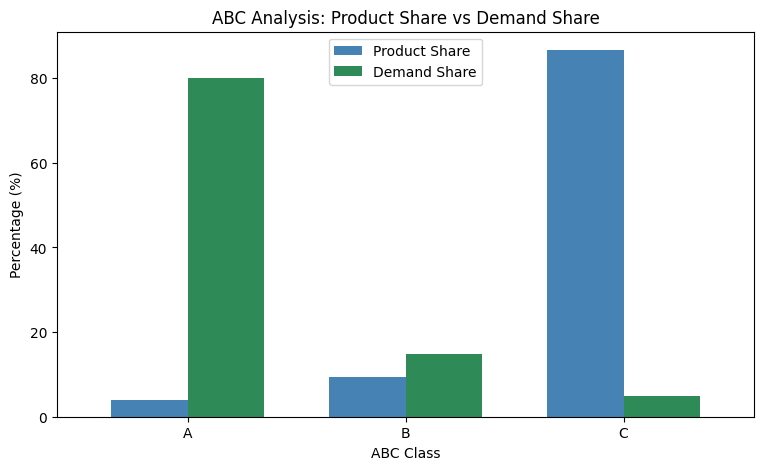

In [6]:
abc_summary[['Product_Share_%', 'Demand_Share_%']].plot(
    kind='bar',
    figsize=(9, 5),
    color=['steelblue', 'seagreen'],
    width=0.7
)

plt.title('ABC Analysis: Product Share vs Demand Share')
plt.xlabel('ABC Class')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.legend(['Product Share', 'Demand Share'])
plt.show()

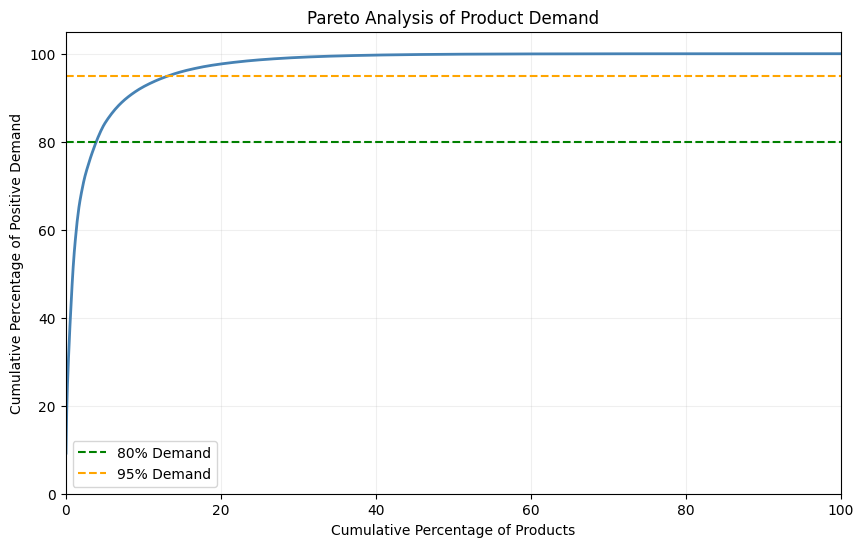

In [7]:
abc['Cumulative_Product_%'] = (
    (abc.index + 1) / len(abc) * 100
)

plt.figure(figsize=(10, 6))

plt.plot(
    abc['Cumulative_Product_%'],
    abc['Cumulative_Demand_%'],
    color='steelblue',
    linewidth=2
)

plt.axhline(80, color='green', linestyle='--', label='80% Demand')
plt.axhline(95, color='orange', linestyle='--', label='95% Demand')

plt.title('Pareto Analysis of Product Demand')
plt.xlabel('Cumulative Percentage of Products')
plt.ylabel('Cumulative Percentage of Positive Demand')
plt.xlim(0, 100)
plt.ylim(0, 105)
plt.legend()
plt.grid(alpha=0.2)
plt.show()

### Key Findings from ABC Analysis

- Class A consists of 86 products, representing only 3.98% of the product portfolio but contributing 80.15% of total positive demand.
- Class B consists of 202 products and contributes 14.87% of total positive demand.
- Class C consists of 1,872 products, representing 86.67% of the product portfolio but contributing only 4.98% of positive demand.
- Classes A and B collectively contribute 95.02% of total positive demand.
- The Pareto curve indicates an exceptionally high concentration of demand among a small proportion of products.

### Business Recommendations

- Prioritise Class A products for inventory monitoring and replenishment planning.
- Maintain regular inventory reviews for Class B products.
- Apply appropriate inventory controls to Class C products to minimise unnecessary stock accumulation.

The classification is based on positive demand quantity rather than monetary consumption value because product prices and costs are unavailable.

## 5.2 XYZ Analysis

In [8]:
monthly_product_demand = df[df['Order_Demand'] > 0].pivot_table(
    index='Product_Code',
    columns=df.loc[df['Order_Demand'] > 0, 'Date'].dt.to_period('M'),
    values='Order_Demand',
    aggfunc='sum',
    fill_value=0
)

monthly_product_demand = monthly_product_demand.reindex(
    columns=pd.period_range('2012-01', '2016-12', freq='M'),
    fill_value=0
)

monthly_product_demand.head()

,2012-01,2012-02,2012-03,2012-04,2012-05,2012-06,2012-07,2012-08,2012-09,2012-10,...,2016-03,2016-04,2016-05,2016-06,2016-07,2016-08,2016-09,2016-10,2016-11,2016-12
Product_Code,,,,,,,,,,,,,,,,,,,,,
Product_0001,9700,13000,14100,3300,9200,6400,10100,9300,6700,16000,...,9300,3400,16900,5300,9300,17500,3300,2100,600,1700
Product_0002,65000,19000,85000,59500,203500,100500,119000,119000,67500,115000,...,82000,1000,142000,83000,57000,53500,91000,97500,59000,137000
Product_0003,400,1200,400,1700,900,300,500,1200,1400,4300,...,1700,2100,1200,1300,1000,2400,2700,1900,5300,900
Product_0004,300,1000,500,0,800,100,500,500,0,1000,...,2400,1100,3000,3900,1900,2200,1700,1300,2000,2900
Product_0005,0,0,0,0,0,100,0,200,0,600,...,400,200,0,0,0,1000,0,300,3800,0


In [9]:
monthly_product_demand.shape

(2160, 60)

In [10]:
xyz = pd.DataFrame({
    'Average_Monthly_Demand': monthly_product_demand.mean(axis=1),
    'Std_Monthly_Demand': monthly_product_demand.std(axis=1, ddof=0),
    'Active_Months': (monthly_product_demand > 0).sum(axis=1)
})

xyz.head().round(2)

,Average_Monthly_Demand,Std_Monthly_Demand,Active_Months
Product_Code,,,
Product_0001,7598.33,3795.06,60
Product_0002,142916.67,143425.71,60
Product_0003,1966.67,1522.35,60
Product_0004,2071.67,1751.10,56
Product_0005,371.67,606.11,34


In [11]:
xyz['CV'] = (
    xyz['Std_Monthly_Demand'] /
    xyz['Average_Monthly_Demand']
)

xyz.head(10).round(2)

,Average_Monthly_Demand,Std_Monthly_Demand,Active_Months,CV
Product_Code,,,,
Product_0001,7598.33,3795.06,60,0.50
Product_0002,142916.67,143425.71,60,1.00
Product_0003,1966.67,1522.35,60,0.77
Product_0004,2071.67,1751.10,56,0.85
Product_0005,371.67,606.11,34,1.63
Product_0006,126.67,177.83,27,1.40
Product_0007,3353.33,1515.53,60,0.45
Product_0008,8425.00,4446.75,60,0.53
Product_0009,781.67,598.75,55,0.77


In [12]:
xyz['CV'].describe().round(2)

count    2160.00
mean        1.26
std         0.94
min         0.13
25%         0.68
50%         1.01
75%         1.49
max         7.68
Name: CV, dtype: float64

In [13]:
xyz['XYZ_Class'] = np.select(
    [
        xyz['CV'] <= 0.5,
        xyz['CV'] <= 1
    ],
    ['X', 'Y'],
    default='Z'
)

xyz.head(10).round(2)

,Average_Monthly_Demand,Std_Monthly_Demand,Active_Months,CV,XYZ_Class
Product_Code,,,,,
Product_0001,7598.33,3795.06,60,0.50,X
Product_0002,142916.67,143425.71,60,1.00,Z
Product_0003,1966.67,1522.35,60,0.77,Y
Product_0004,2071.67,1751.10,56,0.85,Y
Product_0005,371.67,606.11,34,1.63,Z
Product_0006,126.67,177.83,27,1.40,Z
Product_0007,3353.33,1515.53,60,0.45,X
Product_0008,8425.00,4446.75,60,0.53,Y
Product_0009,781.67,598.75,55,0.77,Y


In [14]:
xyz['Total_Positive_Demand'] = monthly_product_demand.sum(axis=1)

xyz_summary = xyz.groupby('XYZ_Class').agg(
    Total_Products=('CV', 'count'),
    Total_Demand=('Total_Positive_Demand', 'sum'),
    Average_CV=('CV', 'mean'),
    Average_Active_Months=('Active_Months', 'mean')
)

xyz_summary['Product_Share_%'] = (
    xyz_summary['Total_Products'] /
    xyz_summary['Total_Products'].sum() * 100
)

xyz_summary['Demand_Share_%'] = (
    xyz_summary['Total_Demand'] /
    xyz_summary['Total_Demand'].sum() * 100
)

xyz_summary.round(2)

,Total_Products,Total_Demand,Average_CV,Average_Active_Months,Product_Share_%,Demand_Share_%
XYZ_Class,,,,,,
X,260,3671118174,0.38,59.93,12.04,71.83
Y,806,1204824453,0.75,57.61,37.31,23.57
Z,1094,234838547,1.84,39.45,50.65,4.59


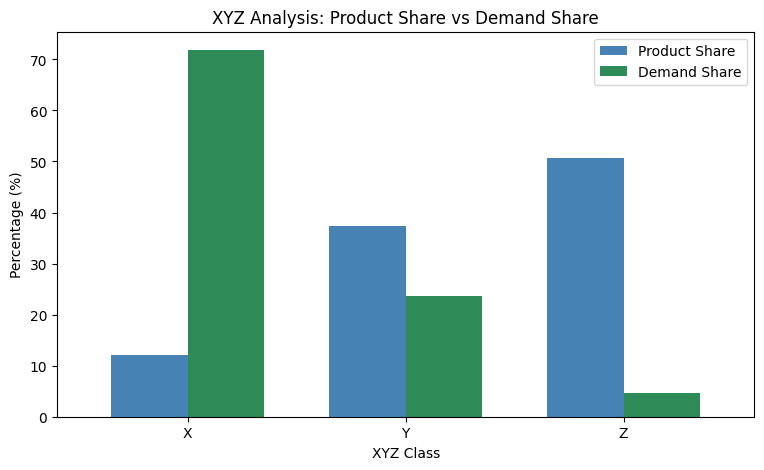

In [15]:
xyz_summary[['Product_Share_%', 'Demand_Share_%']].plot(
    kind='bar',
    figsize=(9, 5),
    color=['steelblue', 'seagreen'],
    width=0.7
)

plt.title('XYZ Analysis: Product Share vs Demand Share')
plt.xlabel('XYZ Class')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.legend(['Product Share', 'Demand Share'])
plt.show()

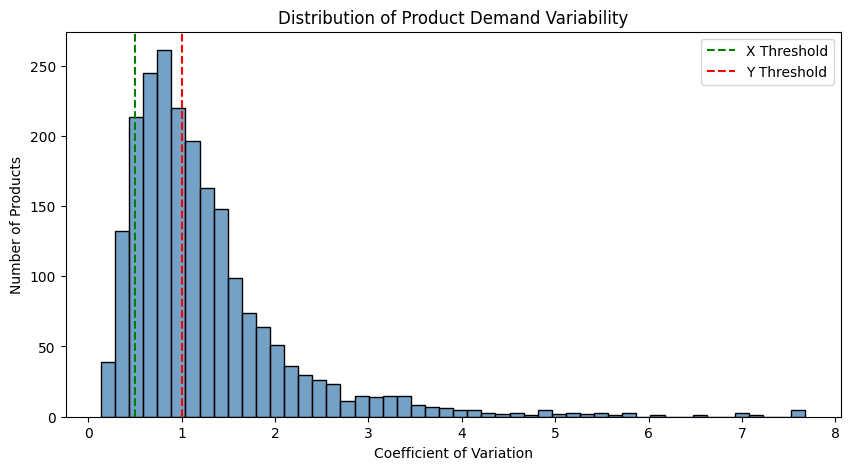

In [16]:
plt.figure(figsize=(10, 5))

sns.histplot(
    xyz['CV'],
    bins=50,
    color='steelblue'
)

plt.axvline(0.5, color='green', linestyle='--', label='X Threshold')
plt.axvline(1.0, color='red', linestyle='--', label='Y Threshold')

plt.title('Distribution of Product Demand Variability')
plt.xlabel('Coefficient of Variation')
plt.ylabel('Number of Products')
plt.legend()
plt.show()

In [17]:
xyz.sort_values('CV').head(10).round(2)

,Average_Monthly_Demand,Std_Monthly_Demand,Active_Months,CV,XYZ_Class,Total_Positive_Demand
Product_Code,,,,,,
Product_1359,7858200.00,1045057.78,60,0.13,X,471492000
Product_1377,936766.67,126516.11,60,0.14,X,56206000
Product_1451,1530450.00,210583.03,60,0.14,X,91827000
Product_1274,1546383.33,225982.01,60,0.15,X,92783000
Product_1382,1360370.00,242386.00,60,0.18,X,81622200
Product_1294,1306513.33,234548.30,60,0.18,X,78390800
Product_1360,1025966.67,186350.38,60,0.18,X,61558000
Product_1378,1391316.67,255162.36,60,0.18,X,83479000
Product_1295,2044125.00,376759.88,60,0.18,X,122647500


In [18]:
xyz.sort_values('CV', ascending=False).head(10).round(2)

,Average_Monthly_Demand,Std_Monthly_Demand,Active_Months,CV,XYZ_Class,Total_Positive_Demand
Product_Code,,,,,,
Product_1703,0.03,0.26,1,7.68,Z,2
Product_2099,2.72,20.87,1,7.68,Z,163
Product_0853,0.33,2.56,1,7.68,Z,20
Product_0465,0.05,0.38,1,7.68,Z,3
Product_1019,1334.33,10215.38,4,7.66,Z,80060
Product_1912,4.83,34.62,2,7.16,Z,290
Product_2098,23.63,167.01,7,7.07,Z,1418
Product_0234,5.45,38.44,4,7.05,Z,327
Product_1799,20.05,139.64,10,6.96,Z,1203


In [19]:
xyz.sort_values('CV', ascending=False).head(10).round(2)

,Average_Monthly_Demand,Std_Monthly_Demand,Active_Months,CV,XYZ_Class,Total_Positive_Demand
Product_Code,,,,,,
Product_1703,0.03,0.26,1,7.68,Z,2
Product_2099,2.72,20.87,1,7.68,Z,163
Product_0853,0.33,2.56,1,7.68,Z,20
Product_0465,0.05,0.38,1,7.68,Z,3
Product_1019,1334.33,10215.38,4,7.66,Z,80060
Product_1912,4.83,34.62,2,7.16,Z,290
Product_2098,23.63,167.01,7,7.07,Z,1418
Product_0234,5.45,38.44,4,7.05,Z,327
Product_1799,20.05,139.64,10,6.96,Z,1203


### Key Findings from XYZ Analysis

- Class X consists of 260 products, representing 12.04% of the product portfolio and contributing 71.83% of total positive demand.
- Class Y consists of 806 products with moderately variable demand, contributing 23.57% of positive demand.
- Class Z consists of 1,094 products, representing 50.65% of all products but contributing only 4.59% of positive demand.
- Class X products recorded positive demand in approximately 60 months on average, compared to 39.45 months for Class Z products.
- Product_1359 recorded the lowest coefficient of variation at approximately 0.13, indicating relatively stable monthly demand.
- Several products with the highest CV values recorded positive demand in only one month.

### Business Recommendations

- Establish regular inventory reviews for products with stable demand.
- Monitor demand fluctuations closely for Class Y products.
- Review purchasing and replenishment requirements carefully for Class Z products.
- Consider both demand volume and demand variability when determining inventory planning priorities.

### Analytical Limitations

Months without positive demand records were treated as zero recorded positive demand. Product launch dates, discontinuation dates and availability information are not provided. Therefore, high demand variability may partly reflect shorter product histories rather than genuinely irregular demand.

The XYZ classification thresholds of 0.50 and 1.00 are selected analytical thresholds rather than universal industry standards.

## 5.3 Combined ABC-XYZ Analysis

In [20]:
abc_xyz = abc.merge(
    xyz.drop(columns='Total_Positive_Demand').reset_index(),
    on='Product_Code',
    how='inner',
    validate='one_to_one'
)

abc_xyz.head(10).round(2)

,Product_Code,Product_Category,Total_Positive_Demand,Demand_Share_%,Cumulative_Demand_%,ABC_Class,Cumulative_Product_%,Average_Monthly_Demand,Std_Monthly_Demand,Active_Months,CV,XYZ_Class
0,Product_1359,Category_019,471492000,9.23,9.23,A,0.05,7858200.00,1045057.78,60,0.13,X
1,Product_1248,Category_019,289022000,5.66,14.88,A,0.09,4817033.33,1410347.84,60,0.29,X
2,Product_0083,Category_019,210539000,4.12,19.00,A,0.14,3508983.33,1014197.26,60,0.29,X
3,Product_1341,Category_019,166411000,3.26,22.26,A,0.19,2773516.67,1262779.19,60,0.46,X
4,Product_1295,Category_019,122647500,2.40,24.66,A,0.23,2044125.00,376759.88,60,0.18,X
5,Product_1241,Category_019,116501000,2.28,26.94,A,0.28,1941683.33,549707.63,60,0.28,X
6,Product_1245,Category_019,102337000,2.00,28.94,A,0.32,1705616.67,963208.81,59,0.56,Y
7,Product_1286,Category_019,101449100,1.99,30.92,A,0.37,1690818.33,311663.25,60,0.18,X
8,Product_1432,Category_019,96928000,1.90,32.82,A,0.42,1615466.67,1051822.06,60,0.65,Y
9,Product_1274,Category_019,92783000,1.82,34.63,A,0.46,1546383.33,225982.01,60,0.15,X


In [21]:
abc_xyz['ABC_XYZ_Class'] = (
    abc_xyz['ABC_Class'] + abc_xyz['XYZ_Class']
)

abc_xyz.head(10).round(2)

,Product_Code,Product_Category,Total_Positive_Demand,Demand_Share_%,Cumulative_Demand_%,ABC_Class,Cumulative_Product_%,Average_Monthly_Demand,Std_Monthly_Demand,Active_Months,CV,XYZ_Class,ABC_XYZ_Class
0,Product_1359,Category_019,471492000,9.23,9.23,A,0.05,7858200.00,1045057.78,60,0.13,X,AX
1,Product_1248,Category_019,289022000,5.66,14.88,A,0.09,4817033.33,1410347.84,60,0.29,X,AX
2,Product_0083,Category_019,210539000,4.12,19.00,A,0.14,3508983.33,1014197.26,60,0.29,X,AX
3,Product_1341,Category_019,166411000,3.26,22.26,A,0.19,2773516.67,1262779.19,60,0.46,X,AX
4,Product_1295,Category_019,122647500,2.40,24.66,A,0.23,2044125.00,376759.88,60,0.18,X,AX
5,Product_1241,Category_019,116501000,2.28,26.94,A,0.28,1941683.33,549707.63,60,0.28,X,AX
6,Product_1245,Category_019,102337000,2.00,28.94,A,0.32,1705616.67,963208.81,59,0.56,Y,AY
7,Product_1286,Category_019,101449100,1.99,30.92,A,0.37,1690818.33,311663.25,60,0.18,X,AX
8,Product_1432,Category_019,96928000,1.90,32.82,A,0.42,1615466.67,1051822.06,60,0.65,Y,AY
9,Product_1274,Category_019,92783000,1.82,34.63,A,0.46,1546383.33,225982.01,60,0.15,X,AX


In [22]:
abc_xyz_summary = abc_xyz.groupby('ABC_XYZ_Class').agg(
    Total_Products=('Product_Code', 'count'),
    Total_Demand=('Total_Positive_Demand', 'sum'),
    Average_CV=('CV', 'mean'),
    Average_Active_Months=('Active_Months', 'mean')
)

abc_xyz_summary['Product_Share_%'] = (
    abc_xyz_summary['Total_Products'] /
    abc_xyz_summary['Total_Products'].sum() * 100
)

abc_xyz_summary['Demand_Share_%'] = (
    abc_xyz_summary['Total_Demand'] /
    abc_xyz_summary['Total_Demand'].sum() * 100
)

abc_xyz_summary.round(2)

,Total_Products,Total_Demand,Average_CV,Average_Active_Months,Product_Share_%,Demand_Share_%
ABC_XYZ_Class,,,,,,
AX,60,3276784950,0.31,60.00,2.78,64.12
AY,24,788941250,0.67,59.79,1.11,15.44
AZ,2,30798750,1.27,60.00,0.09,0.60
BX,80,344271475,0.38,59.94,3.70,6.74
BY,82,291824835,0.70,58.46,3.80,5.71
BZ,40,123680500,1.38,49.80,1.85,2.42
CX,120,50061749,0.42,59.90,5.56,0.98
CY,700,124058368,0.76,57.44,32.41,2.43
CZ,1052,80359297,1.85,39.02,48.70,1.57


In [23]:
product_matrix = pd.crosstab(
    abc_xyz['ABC_Class'],
    abc_xyz['XYZ_Class']
).reindex(
    index=['A', 'B', 'C'],
    columns=['X', 'Y', 'Z'],
    fill_value=0
)

product_matrix

XYZ_Class,X,Y,Z
ABC_Class,,,
A,60,24,2
B,80,82,40
C,120,700,1052


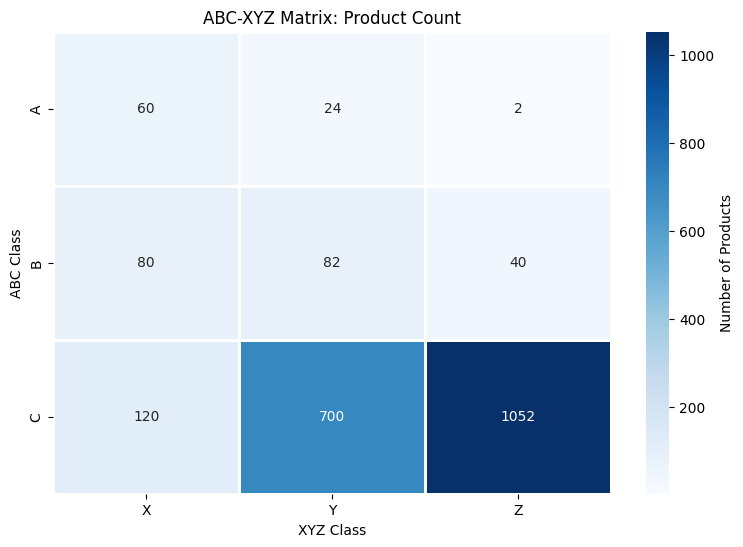

In [24]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    product_matrix,
    annot=True,
    fmt='d',
    cmap='Blues',
    linewidths=1,
    cbar_kws={'label': 'Number of Products'}
)

plt.title('ABC-XYZ Matrix: Product Count')
plt.xlabel('XYZ Class')
plt.ylabel('ABC Class')
plt.show()

In [25]:
demand_matrix = abc_xyz.pivot_table(
    index='ABC_Class',
    columns='XYZ_Class',
    values='Total_Positive_Demand',
    aggfunc='sum',
    fill_value=0
).reindex(
    index=['A', 'B', 'C'],
    columns=['X', 'Y', 'Z'],
    fill_value=0
)

demand_matrix_pct = (
    demand_matrix / demand_matrix.to_numpy().sum() * 100
)

demand_matrix_pct.round(2)

XYZ_Class,X,Y,Z
ABC_Class,,,
A,64.12,15.44,0.60
B,6.74,5.71,2.42
C,0.98,2.43,1.57


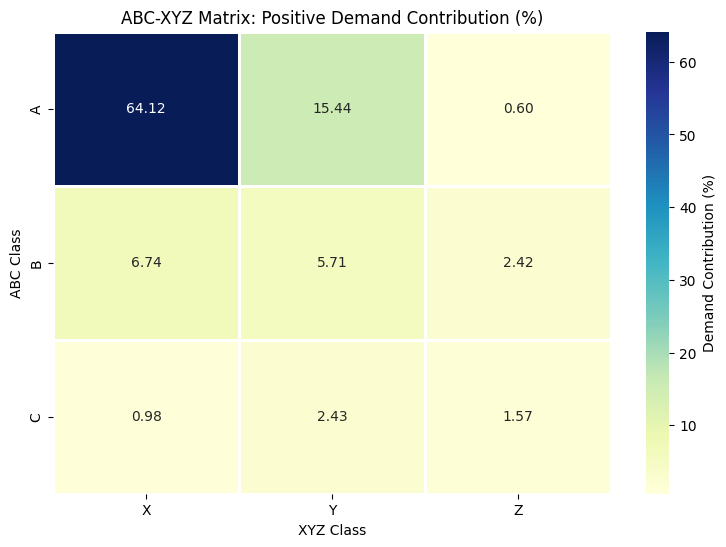

In [26]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    demand_matrix_pct,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu',
    linewidths=1,
    cbar_kws={'label': 'Demand Contribution (%)'}
)

plt.title('ABC-XYZ Matrix: Positive Demand Contribution (%)')
plt.xlabel('XYZ Class')
plt.ylabel('ABC Class')
plt.show()

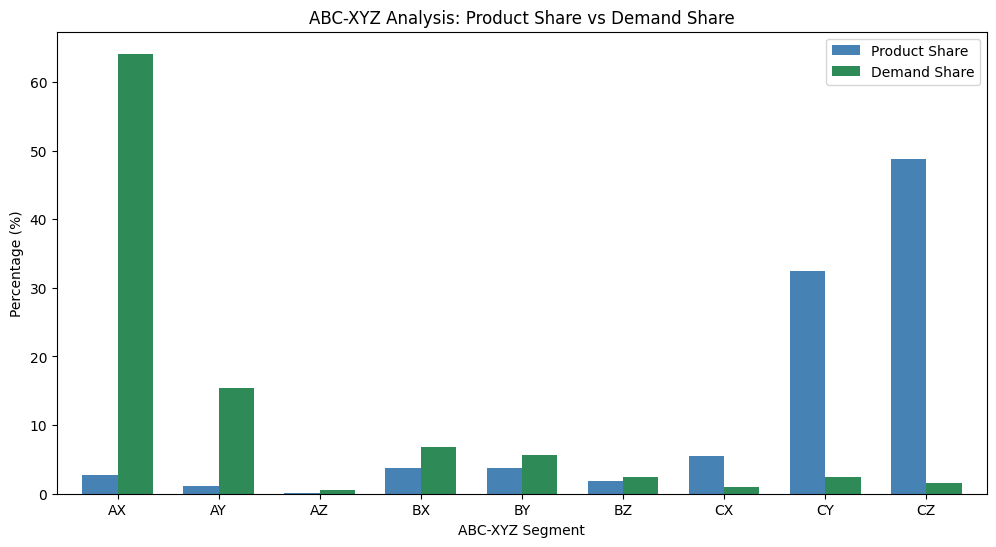

In [27]:
abc_xyz_summary[['Product_Share_%', 'Demand_Share_%']].plot(
    kind='bar',
    figsize=(12, 6),
    color=['steelblue', 'seagreen'],
    width=0.7
)

plt.title('ABC-XYZ Analysis: Product Share vs Demand Share')
plt.xlabel('ABC-XYZ Segment')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.legend(['Product Share', 'Demand Share'])
plt.show()

In [28]:
az_products = abc_xyz[
    abc_xyz['ABC_XYZ_Class'] == 'AZ'
].sort_values('Total_Positive_Demand', ascending=False)

az_products[[
    'Product_Code',
    'Product_Category',
    'Total_Positive_Demand',
    'Average_Monthly_Demand',
    'Active_Months',
    'CV',
    'ABC_XYZ_Class'
]].round(2)

,Product_Code,Product_Category,Total_Positive_Demand,Average_Monthly_Demand,Active_Months,CV,ABC_XYZ_Class
50,Product_0094,Category_019,18617750,310295.83,60,1.09,AZ
70,Product_1465,Category_019,12181000,203016.67,60,1.45,AZ


In [29]:
strategies = {
    'AX': 'Regular replenishment and close monitoring',
    'AY': 'Flexible replenishment and frequent reviews',
    'AZ': 'Priority demand monitoring and variability review',
    'BX': 'Standard replenishment',
    'BY': 'Periodic inventory reviews',
    'BZ': 'Controlled purchasing and demand monitoring',
    'CX': 'Simplified replenishment',
    'CY': 'Periodic stock reviews',
    'CZ': 'Requirement-based purchasing review'
}

abc_xyz['Inventory_Strategy'] = (
    abc_xyz['ABC_XYZ_Class'].map(strategies)
)

abc_xyz[[
    'Product_Code',
    'ABC_XYZ_Class',
    'Inventory_Strategy'
]].head(10)

,Product_Code,ABC_XYZ_Class,Inventory_Strategy
0,Product_1359,AX,Regular replenishment and close monitoring
1,Product_1248,AX,Regular replenishment and close monitoring
2,Product_0083,AX,Regular replenishment and close monitoring
3,Product_1341,AX,Regular replenishment and close monitoring
4,Product_1295,AX,Regular replenishment and close monitoring
5,Product_1241,AX,Regular replenishment and close monitoring
6,Product_1245,AY,Flexible replenishment and frequent reviews
7,Product_1286,AX,Regular replenishment and close monitoring
8,Product_1432,AY,Flexible replenishment and frequent reviews
9,Product_1274,AX,Regular replenishment and close monitoring


In [30]:
print('Total Products:', abc_xyz['Product_Code'].nunique())

print('Duplicate Products:',
      abc_xyz['Product_Code'].duplicated().sum())

print('Total Positive Demand:',
      abc_xyz['Total_Positive_Demand'].sum())

abc_xyz.isnull().sum()

Total Products: 2160
Duplicate Products: 0
Total Positive Demand: 5110781174


Product_Code              0
Product_Category          0
Total_Positive_Demand     0
Demand_Share_%            0
Cumulative_Demand_%       0
ABC_Class                 0
Cumulative_Product_%      0
Average_Monthly_Demand    0
Std_Monthly_Demand        0
Active_Months             0
CV                        0
XYZ_Class                 0
ABC_XYZ_Class             0
Inventory_Strategy        0
dtype: int64

In [32]:
abc_xyz.loc[
    abc_xyz['ABC_XYZ_Class'] == 'AZ',
    ['Product_Code', 'Product_Category',
     'Total_Positive_Demand', 'CV', 'Active_Months']
].round(2)

,Product_Code,Product_Category,Total_Positive_Demand,CV,Active_Months
50,Product_0094,Category_019,18617750,1.09,60
70,Product_1465,Category_019,12181000,1.45,60


### Key Findings from Combined ABC-XYZ Analysis

- All 2,160 products were successfully classified into nine ABC-XYZ segments.
- The AX segment contains only 60 products, representing 2.78% of the product portfolio but contributing 64.12% of total positive demand.
- The AY segment contains 24 products and contributes 15.44% of total positive demand.
- Only two products belong to the AZ segment, combining high demand volume with high monthly demand variability.
- The CZ segment contains 1,052 products, representing 48.70% of the product portfolio but contributing only 1.57% of total positive demand.
- Product_1359 belongs to the AX segment and combines the highest positive demand with the lowest relative demand variability.
- Different product segments require different inventory planning and replenishment strategies.

### Business Recommendations

- Prioritise AX products for regular replenishment and supply continuity planning.
- Monitor AY and AZ products closely because of their demand variability.
- Implement appropriate purchasing controls for low-volume and irregular-demand products.
- Use both demand contribution and demand consistency when establishing inventory planning priorities.

### Analytical Limitations

ABC classification is based on positive demand volume rather than monetary consumption value because product costs are unavailable.

XYZ classification uses selected coefficient of variation thresholds and assumes that months without positive demand records represent zero recorded positive demand.

The recommended inventory strategies are based on historical demand characteristics. Actual inventory levels, lead times, holding costs and service-level requirements are unavailable.

The final classification dataset contains 2,160 unique products, 14 columns and no missing values or duplicate product codes.

### AZ Segment: High-Volume, Highly Variable Products

Product_0094 and Product_1465 are the only two products classified under the AZ segment. Both belong to Category_019 and collectively contribute 30.80 million units of positive demand.

Despite recording positive demand throughout all 60 months, both products exhibit high monthly demand variability. Product_1465 demonstrates greater relative variability, with a coefficient of variation of 1.45 compared to 1.09 for Product_0094.

These products should be prioritised for frequent demand reviews, flexible replenishment planning and inventory risk monitoring.

In [33]:
abc_xyz.to_csv('Product_ABC_XYZ_Classification.csv', index=False)